<a href="https://colab.research.google.com/github/sathiyapriyaprakash/Digitalportfolio/blob/main/RFM_Cohort_Anlaysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **RFM COHORT ANALYSIS**

**Import libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


**Upload dataset**

In [30]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail (1).xlsx


**Load dataset**

In [31]:
df = pd.read_excel("Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**Dataset Information**

In [32]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows:
5268

Statistical Summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


**Data Cleaning**

In [33]:
df = df.drop_duplicates()

df = df.dropna(subset=[
    "CustomerID",
    "InvoiceDate",
    "InvoiceNo",
    "Quantity",
    "UnitPrice"
])

df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
].copy()

df["CustomerID"] = df["CustomerID"].astype(int)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

print("Data Cleaning Completed!")
print("Cleaned Dataset Shape:", df.shape)

df.head()

Data Cleaning Completed!
Cleaned Dataset Shape: (392692, 9)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


**Exploratory Data Analysis(EDA)**

In [47]:
print("Total Customers:", df["CustomerID"].nunique())

print("Total Invoices:", df["InvoiceNo"].nunique())

print("Total Products:", df["StockCode"].nunique())

print("Total Sales:", round(df["TotalAmount"].sum(), 2))

print("First Transaction:", df["InvoiceDate"].min())

print("Last Transaction:", df["InvoiceDate"].max())

Total Customers: 4338
Total Invoices: 18532
Total Products: 3665
Total Sales: 8887208.89
First Transaction: 2010-12-01 08:26:00
Last Transaction: 2011-12-09 12:50:00


**Monthly Sales Analysis**

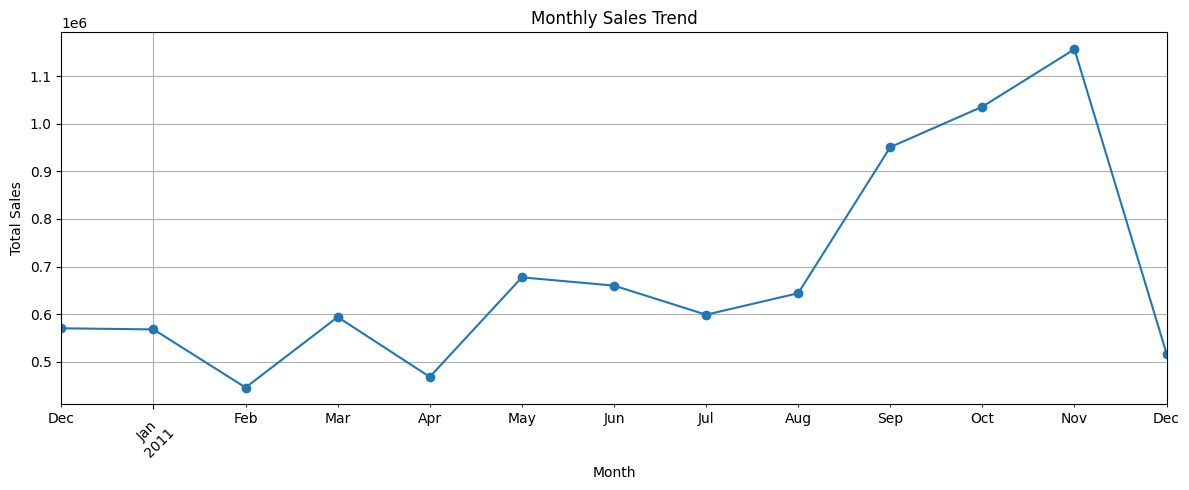

In [48]:
df["InvoiceMonth"] = (
    df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
)

monthly_sales = df.groupby(
    "InvoiceMonth"
)["TotalAmount"].sum()

plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind="line",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**RFM ANALYSIS**

In [49]:
snapshot_date = (
    df["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = df.groupby("CustomerID").agg(
    Recency=(
        "InvoiceDate",
        lambda x: (
            snapshot_date - x.max().normalize()
        ).days
    ),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum")
)

print("RFM Analysis Completed!")

display(rfm.head(10))

RFM Analysis Completed!


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,3,7,4310.00
12348,76,4,1797.24
12349,19,1,1757.55
12350,311,1,334.40
12352,37,8,2506.04
12353,205,1,89.00
12354,233,1,1079.40
12355,215,1,459.40


**RFM Score**

In [39]:
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head())

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12346,326,1,77183.60,1,1,4,114
12347,2,7,4310.00,4,4,4,444
12348,75,4,1797.24,2,3,4,234
12349,19,1,1757.55,3,1,4,314
12350,310,1,334.40,1,1,2,112


**Customer segmentation**

In [40]:
def segment_customer(row):

    if row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Champions"

    elif row["F_Score"] >= 3:
        return "Loyal Customers"

    elif row["R_Score"] <= 2 and row["F_Score"] >= 2:
        return "At Risk"

    elif row["R_Score"] == 1:
        return "Lost Customers"

    else:
        return "Potential Customers"


rfm["Segment"] = rfm.apply(segment_customer, axis=1)

print(rfm["Segment"].value_counts())

rfm.head()

Segment
Champions              1514
Potential Customers     968
At Risk                 682
Loyal Customers         655
Lost Customers          519
Name: count, dtype: int64


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
12346,326,1,77183.60,1,1,4,114,Lost Customers
12347,2,7,4310.00,4,4,4,444,Champions
12348,75,4,1797.24,2,3,4,234,Loyal Customers
12349,19,1,1757.55,3,1,4,314,Potential Customers
12350,310,1,334.40,1,1,2,112,Lost Customers


**RFM segment visualization**

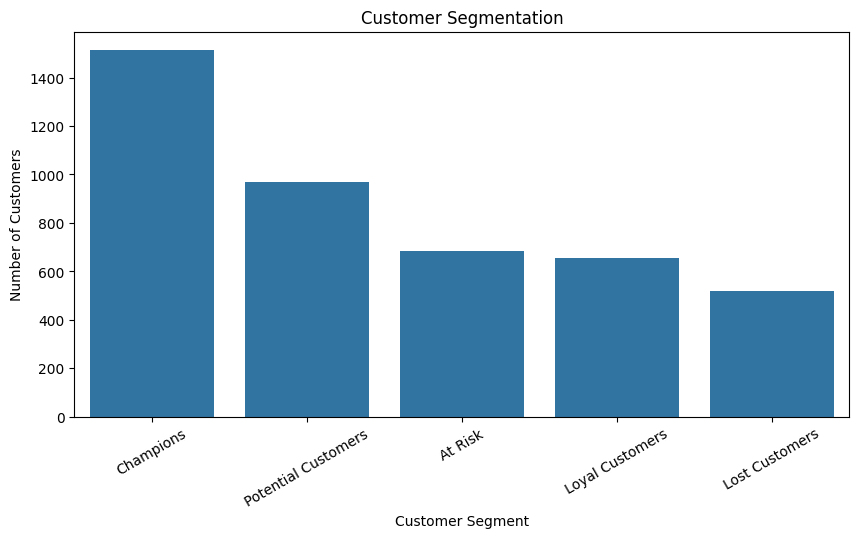

In [41]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=rfm,
    x="Segment",
    order=rfm["Segment"].value_counts().index
)

plt.title("Customer Segmentation")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.show()

**Cohort Analysis**

In [42]:
cohort_df = df.copy()

cohort_df["InvoiceMonth"] = (
    cohort_df["InvoiceDate"].dt.to_period("M")
)

cohort_df["CohortMonth"] = (
    cohort_df.groupby("CustomerID")["InvoiceDate"]
    .transform("min")
    .dt.to_period("M")
)

cohort_df["CohortIndex"] = (
    (cohort_df["InvoiceMonth"].dt.year -
     cohort_df["CohortMonth"].dt.year) * 12
    +
    (cohort_df["InvoiceMonth"].dt.month -
     cohort_df["CohortMonth"].dt.month)
    + 1
)

print("Cohort Groups Created!")
display(cohort_df.head())

Cohort Groups Created!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount,InvoiceMonth,CohortMonth,CohortIndex
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12,2010-12,1
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,2010-12,1
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12,2010-12,1
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,2010-12,1
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12,2010-12,1


**Customer Retention Table**

In [43]:
cohort_counts = cohort_df.groupby(
    ["CohortMonth", "CohortIndex"]
)["CustomerID"].nunique().unstack()

cohort_sizes = cohort_counts.iloc[:, 0]

retention = cohort_counts.divide(
    cohort_sizes, axis=0
) * 100

print("Customer Retention Table (%)")

display(retention.round(2))

Customer Retention Table (%)


CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Retention Heatmap**

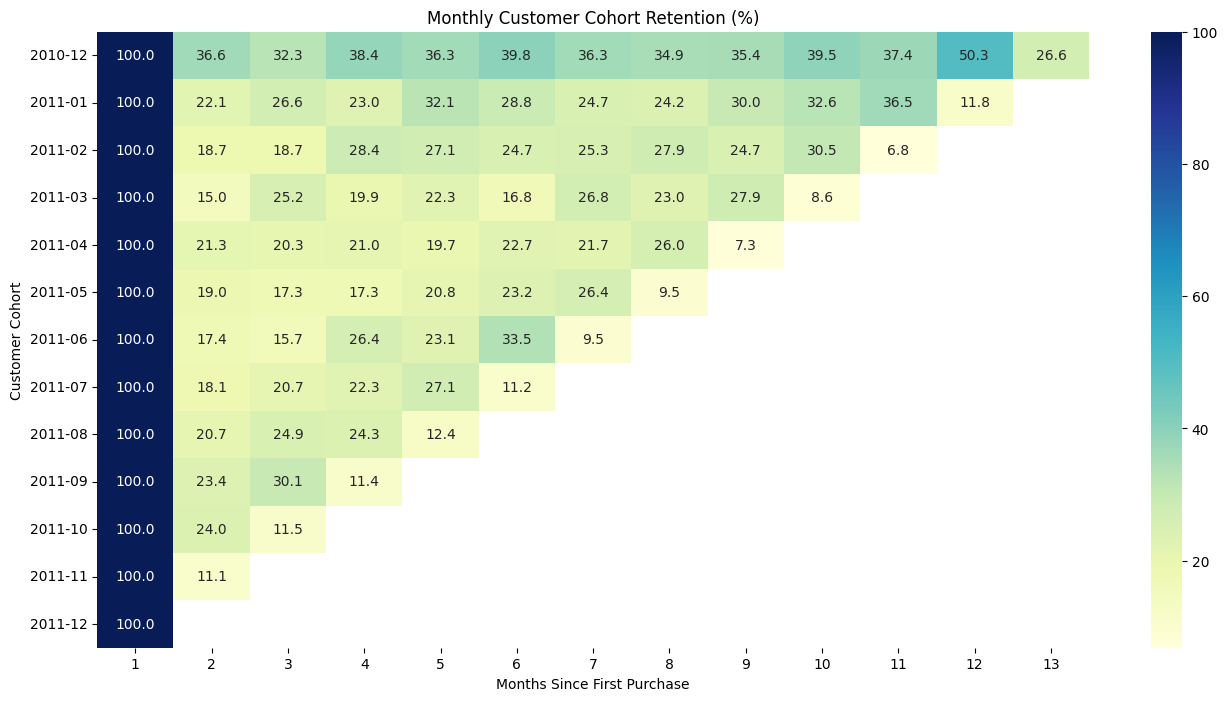

In [44]:
plt.figure(figsize=(16, 8))

sns.heatmap(
    retention,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Monthly Customer Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Cohort")
plt.show()

**Business Insights**

In [45]:
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Segment", "size"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Total_Monetary=("Monetary", "sum")
)

segment_summary["Customer_Percent"] = (
    segment_summary["Customers"]
    / segment_summary["Customers"].sum()
    * 100
)

print("CUSTOMER SEGMENT SUMMARY")

display(segment_summary.round(2))

print("\nBUSINESS INSIGHTS")

print(
    "Total Customers:",
    rfm.shape[0]
)

print(
    "Total Sales:",
    round(df["TotalAmount"].sum(), 2)
)

print(
    "Largest Customer Segment:",
    segment_summary["Customers"].idxmax()
)

print(
    "Highest Revenue Segment:",
    segment_summary["Total_Monetary"].idxmax()
)

CUSTOMER SEGMENT SUMMARY


,Customers,Average_Recency,Average_Frequency,Average_Monetary,Total_Monetary,Customer_Percent
Segment,,,,,,
At Risk,682,173.35,1.56,545.76,372210.94,15.72
Champions,1514,17.55,8.55,4339.46,6569940.81,34.90
Lost Customers,519,262.87,1.00,482.09,250203.72,11.96
Loyal Customers,655,118.26,4.18,1606.72,1052403.65,15.10
Potential Customers,968,44.15,1.31,663.69,642449.77,22.31



BUSINESS INSIGHTS
Total Customers: 4338
Total Sales: 8887208.89
Largest Customer Segment: Champions
Highest Revenue Segment: Champions


In [46]:
rfm.to_csv("rfm_customer_segments.csv")

segment_summary.to_csv("rfm_segment_summary.csv")

cohort_counts.to_csv("cohort_customer_counts.csv")

retention.to_csv("cohort_retention_percent.csv")

print("Project results exported successfully!")

Project results exported successfully!
